In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [2]:
# Crear dataset multiclase
X_multi, y_multi = make_blobs(n_samples=300, centers=3, cluster_std=1.2, random_state=42)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_multi, y_multi, test_size=0.3, random_state=42)

In [3]:
# Grid para graficar fronteras
xxm, yym = np.meshgrid(np.linspace(X_multi[:, 0].min()-1, X_multi[:, 0].max()+1, 500),
                       np.linspace(X_multi[:, 1].min()-1, X_multi[:, 1].max()+1, 500))
gridm = np.c_[xxm.ravel(), yym.ravel()]

In [4]:
# Modelos multiclase
models_multi = [
    ("Modelo A: Regresión logística multinomial", LogisticRegression(multi_class='multinomial', solver='lbfgs')),
    ("Modelo B: Naive Bayes gaussiano", GaussianNB()),
    ("Modelo C: Árbol de decisión (profundidad=3)", DecisionTreeClassifier(max_depth=3)),
    ("Modelo D: Árbol de decisión (sin límite)", DecisionTreeClassifier()),
    ("Modelo E: Random Forest (n=100)", RandomForestClassifier(n_estimators=100, random_state=42)),
]

C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1264: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


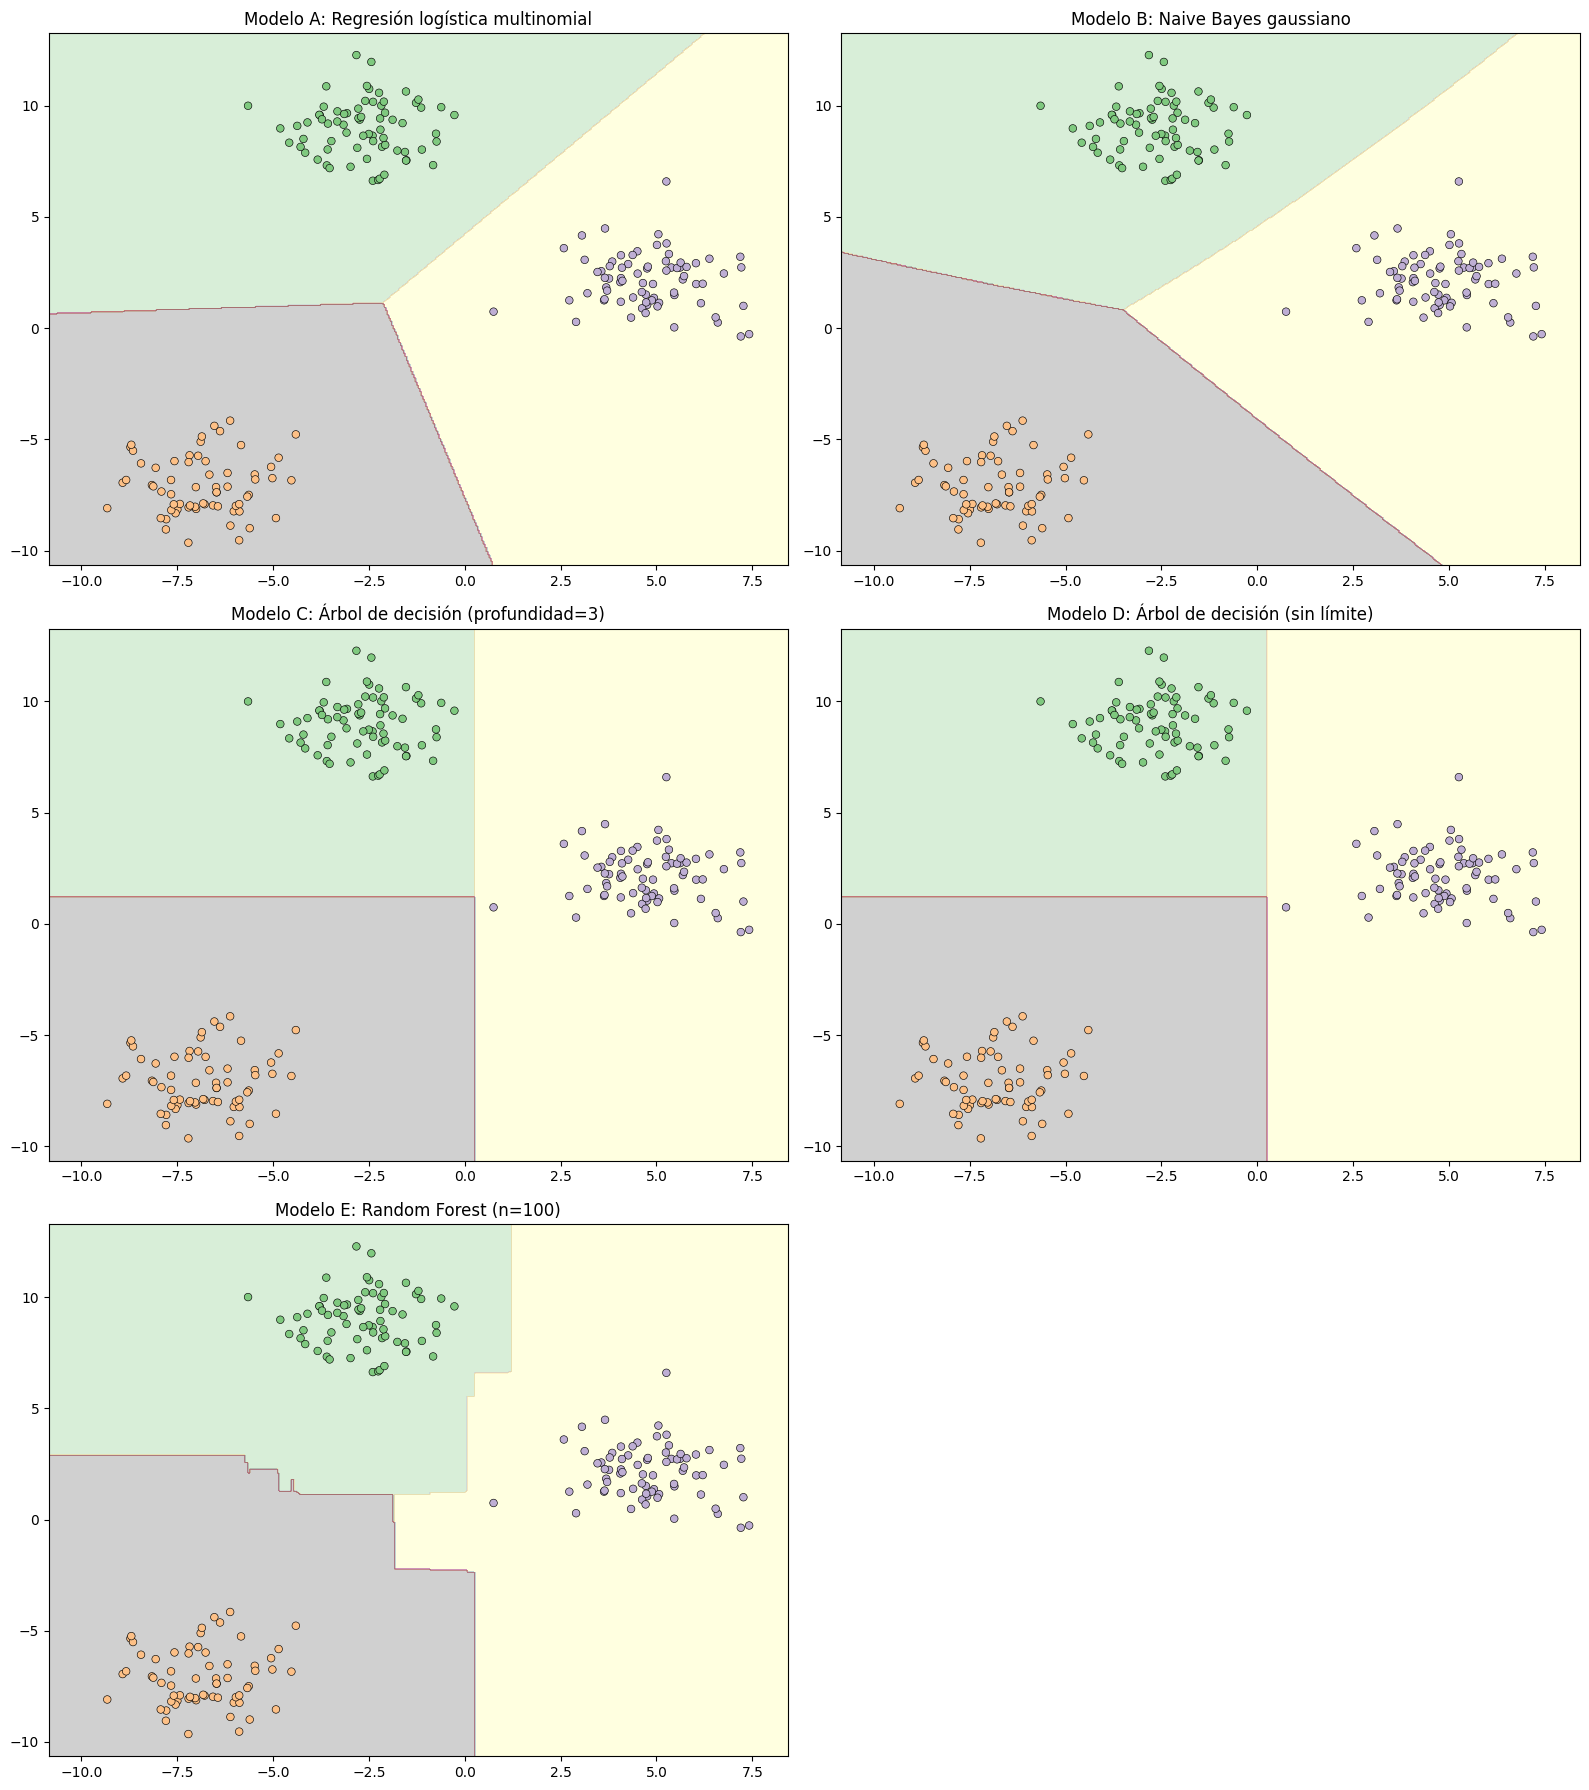

In [5]:
# Graficar clasificación multiclase
fig, axs = plt.subplots(3, 2, figsize=(16, 18))
axs = axs.ravel()

for i, (title, model) in enumerate(models_multi):
    model.fit(Xm_train, ym_train)
    Z = model.predict(gridm).reshape(xxm.shape)

    axs[i].contourf(xxm, yym, Z, alpha=0.3, cmap="Accent")
    sns.scatterplot(x=Xm_train[:, 0], y=Xm_train[:, 1], hue=ym_train, palette="Accent", ax=axs[i], s=30, edgecolor="k", legend=False)
    axs[i].set_title(title)
    axs[i].set_xlim(xxm.min(), xxm.max())
    axs[i].set_ylim(yym.min(), yym.max())

axs[-1].axis("off")
plt.tight_layout()
plt.show()